# 橫截面預測:波動度 vs 報酬 —— 同一個 Random Forest,只換預測標的

這本 notebook 問一個很窄的問題:

> 當一個模型在真實資料上失敗,是模型不夠好,還是**標的本身不可預測**?

做法是把變數鎖到只剩一個。同一組 20 個特徵、同一套 walk-forward、
同一組 RandomForest 超參數、同一份 Russell 3000 真實日線(2007–2024),
**只換 `y`**:

| | 任務 A | 任務 B |
|---|---|---|
| `y` | 下月報酬的橫截面排序 | 下月已實現波動的橫截面排序 |
| 特徵 | 完全相同的 20 個 | 完全相同的 20 個 |
| 模型 | `RandomForestRegressor` 同一組參數 | 同上 |
| 預期 | 失敗 | 成功 |

兩個 `y` 都被壓成同一個尺度(每月橫截面排序 → `[0,1]`),所以 $R^2$ 與 IC
可以直接並排比較 —— 這是整本 notebook 唯一的實驗設計重點。

## 結構

| 部分 | 內容 |
|---|---|
| 第 0 部分 | 環境、資料、逐年涵蓋數、存活者偏誤警告 |
| 第 1 部分 | **先在合成資料上驗證 RF 的機制**:bagging 的變異數下降、feature importance 能不能復原藏進去的權重、以及把噪音從 σ=0.1 拉到 5.0 的 $R^2$ 衰減曲線 |
| 第 2 部分 | 真實資料的特徵工程:只用 OHLCV 造 20 個特徵,月底結算 |
| 第 3 部分 | Walk-forward 訓練與兩個任務的對比(**核心**) |
| 第 4 部分 | 任務 A 的現實檢驗:十分位多空、扣交易成本、對標純動能 |
| 第 5 部分 | 任務 B 成功了,然後呢:校準、等風險 sizing、選擇權權利金品質 |
| 第 6 部分 | 模型診斷:permutation importance、學習曲線、OOB |

第 1 部分的角色和 CNN notebook 的「用假輸入逐層驗證形狀」一樣:
**在碰真實資料前,先證明模型本身沒壞**。這樣第 3 部分任務 A 失敗的時候,
「模型寫錯了」這個解釋已經被排除掉了。

---
# 第 0 部分:環境與資料

價格資料走集中式 loader,**不硬編 parquet 路徑**
(`price.py` 的 docstring 明文禁止,它是這台機器上美股價格的唯一出口)。

```python
from aws_fetch_price_data.fetch_fmp_price.price import load_us_price_data
px = load_us_price_data(history="long")   # 2007-01-03 ~ 2024-12-31
```

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
# 讓 matplotlib 畫得出中文
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang HK", "Heiti TC", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10, "axes.titlesize": 11})

ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
def savefig(fig, name):
    """圖同時存進 assets/,README 直接引用同一份檔案。"""
    fig.savefig(ASSETS / f"{name}.png", dpi=130, bbox_inches="tight")

SEED = 42
SQ252 = np.sqrt(252.0)
print("python  ", sys.version.split()[0])
import sklearn, scipy
print("pandas  ", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| scipy", scipy.__version__)

python   3.13.13
pandas   3.0.1 | numpy 2.1.3 | sklearn 1.9.1 | scipy 1.15.3


In [2]:
sys.path.insert(0, "/Users/hsieh/Desktop/KICKs")
from aws_fetch_price_data.fetch_fmp_price.price import load_us_price_data

t0 = time.time()
px = load_us_price_data(history="long")
print(f"load_us_price_data(history='long')  {time.time()-t0:.1f}s")
print("shape           ", px.shape)
print("columns levels  ", px.columns.names, "->", px.columns.levels[0].tolist())
print("date range      ", px.index[0].date(), "~", px.index[-1].date(),
      f"({len(px.index)} 個交易日)")
print("tickers         ", px.columns.levels[1].size)
px["Close"].iloc[:3, :6]

load_us_price_data(history='long')  1.2s
shape            (4530, 13305)
columns levels   ['Price', 'Ticker'] -> ['Close', 'High', 'Low', 'Open', 'Volume']
date range       2007-01-03 ~ 2024-12-31 (4530 個交易日)
tickers          2661


Ticker,A,AA,AAL,AAMI,AAOI,AAON
Date,,,,,,
2007-01-03,21.842001,58.011890,53.076351,NaN,NaN,2.939646
2007-01-04,21.912048,57.576771,55.470913,NaN,NaN,2.976074
2007-01-05,21.708269,56.884506,54.952400,NaN,NaN,2.897699


## 0.1 逐年涵蓋數

這份 panel 不是等寬的:2007 年只有 ~1,400 檔有價格,2024 年有 ~2,600 檔。
原因是今天的 Russell 3000 成分股裡有很多公司在 2007 年還沒上市。

Date
2007    1415
2008    1458
2009    1475
2010    1514
2011    1555
2012    1595
2013    1655
2014    1747
2015    1833
2016    1894
2017    1966
2018    2060
2019    2142
2020    2238
2021    2427
2022    2534
2023    2565
2024    2602


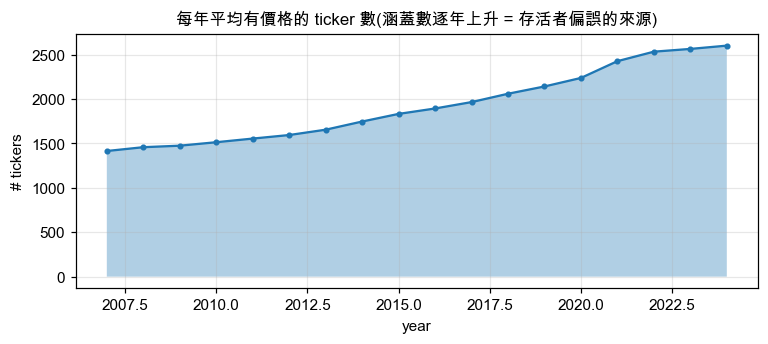

In [3]:
close_raw = px["Close"].astype("float64")
cov = close_raw.notna().sum(axis=1).groupby(close_raw.index.year).mean().round(0).astype(int)
print(cov.to_string())

fig, ax = plt.subplots(figsize=(8, 3))
ax.fill_between(cov.index, cov.values, alpha=0.35)
ax.plot(cov.index, cov.values, "o-", ms=3)
ax.set_title("每年平均有價格的 ticker 數(涵蓋數逐年上升 = 存活者偏誤的來源)")
ax.set_xlabel("year"); ax.set_ylabel("# tickers")
savefig(fig, "01-coverage"); plt.show()

## 0.2 存活者偏誤 —— 先把話說清楚

**這份 universe 是「今天的 Russell 3000」回填到 2007 年。**
2008–2024 之間下市、被併、破產、被踢出指數的公司**不在裡面**。

後果分兩邊:

- **對任務 A(報酬)影響大**:倒掉的公司通常是跌最慘的那一批。少了它們,
  橫截面的左尾被截掉,動能/反轉類特徵看起來會比真實情況更有效。
  也就是說,第 3 部分任務 A 的結果是**偏樂觀**的版本 —— 連偏樂觀都做不出來。
- **對任務 B(波動)影響小**:波動度的持續性是個股自身的統計性質,
  不是靠橫截面的贏家輸家排序。少了下市公司會讓高波動端的樣本變少,
  但不會翻轉「本月高波動 → 下月高波動」這個關係。

這個偏誤沒辦法在這份資料裡修掉(要修需要 point-in-time 的指數成分表),
所以處理方式是:**標記它,並且讓它只往對結論不利的方向偏**。

---
# 第 1 部分:在合成資料上驗證 RF 的機制

這一節**不碰真實資料**,目的只有一個:在跑真實資料之前,
先確認模型、評估、importance 這三件事本身是對的。

合成 panel 的結構直接照搬**這個 repo 的前身**(改名前叫 Decision-Tree-Factor-Regression,
舊程式 `desision_model.py` 裡的 `generate_pseudo_factor_panel` 還在 git 歷史裡):
6 個橫截面因子、權重寫死、加三個非線性項、加高斯噪音。
那份舊的在合成資料上跑出 Sharpe 27.8、36 個月零虧損、樣本外 $R^2$ 0.67 ——
數字是真的,它只是證明了決策樹找得回自己藏的結構。

$$y = \underbrace{\sum_f w_f z_f}_{\text{線性}} + \underbrace{0.10\,(z_{mom}\cdot -z_{vol}) - 0.05\,z_{liq}^2 + 0.08\,z_{val}^+ z_{qual}^+}_{\text{非線性}} + \underbrace{\varepsilon}_{\mathcal{N}(0,\sigma^2)}$$

因為噪音是我自己加的,**$R^2$ 的理論上限是算得出來的**:

$$R^2_{\max} = \frac{\mathrm{Var}(\text{signal})}{\mathrm{Var}(\text{signal}) + \sigma^2}$$

這條上限是整個第 1 部分的量尺 —— 模型跑出來的 $R^2$ 要貼近它,才算機制正常。

In [4]:
TRUE_W = {"value": 0.34, "momentum": 0.39, "size": -0.21,
          "quality": 0.25, "volatility": -0.14, "liquidity": 0.11}
FAC = list(TRUE_W)

def make_panel(n_stocks=200, n_months=120, sigma=0.25, seed=0):
    """造一個結構已知的 panel:線性 + 非線性 + 噪音。回傳 (X, y, 無噪音的真訊號)。"""
    rng = np.random.default_rng(seed)
    n = n_stocks * n_months
    Z = rng.normal(0, 1, (n, len(FAC)))
    Z = (Z - Z.mean(0)) / Z.std(0)              # 橫截面標準化
    d = dict(zip(FAC, Z.T))
    linear = sum(TRUE_W[f] * d[f] for f in FAC)
    nonlinear = (0.10 * (d["momentum"] * -d["volatility"])
                 - 0.05 * d["liquidity"] ** 2
                 + 0.08 * np.maximum(d["value"], 0) * np.maximum(d["quality"], 0))
    signal = linear + nonlinear
    y = signal + rng.normal(0, sigma, n)
    X = pd.DataFrame(Z, columns=FAC)
    X["month"] = np.repeat(np.arange(n_months), n_stocks)
    return X, pd.Series(y, name="y"), pd.Series(signal, name="signal")

Xs, ys, sig = make_panel()
tr_s = Xs["month"] < 84                          # 前 7 年訓練、後 3 年樣本外
Xtr_s, Xte_s = Xs.loc[tr_s, FAC].values, Xs.loc[~tr_s, FAC].values
ytr_s, yte_s = ys[tr_s].values, ys[~tr_s].values
ceiling = sig.var() / (sig.var() + 0.25 ** 2)
print(f"訓練 {Xtr_s.shape}  樣本外 {Xte_s.shape}")
print(f"Var(signal)={sig.var():.4f}  σ²={0.0625:.4f}  ->  R² 理論上限 = {ceiling:.3f}")

訓練 (16800, 6)  樣本外 (7200, 6)
Var(signal)=0.4436  σ²=0.0625  ->  R² 理論上限 = 0.877


## 1.1 單棵樹 vs 300 棵樹 —— bagging 的全部價值

Random Forest 相對單棵 Decision Tree 多的東西只有兩個:
**bootstrap 重抽樣** 與 **每次分裂只看 `max_features` 個特徵**。
兩者都是為了讓樹彼此去相關,然後平均掉「樹自己的變異數」。

單棵深樹是個低偏誤、高變異數的估計器:換一個隨機種子,預測就變一大片。
下面直接把這件事量出來 —— 右圖的 y 軸是**同一個測試點、5 個不同種子下預測值的標準差**,
如果 bagging 真的在平均獨立誤差,它應該以 $1/\sqrt{n}$ 衰減。

單棵樹(看全部特徵、無 bootstrap)  OOS R² = 0.730
RF   1 棵(sqrt 特徵 + bootstrap)  OOS R² = 0.644
RF 300 棵                          OOS R² = 0.807   (理論上限 0.877)
預測標準差 1 棵 0.2323 -> 300 棵 0.0130  (縮小 17.9 倍,√300 = 17.3)


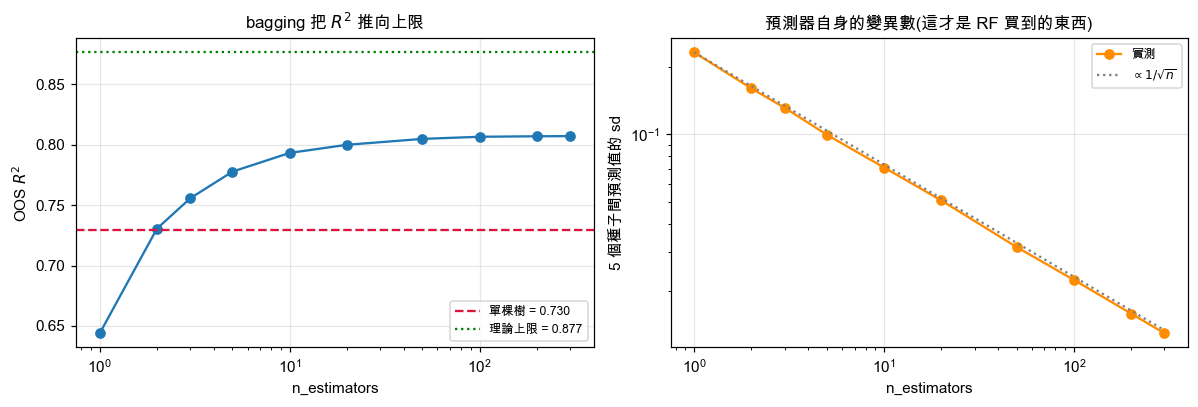

In [5]:
ns_trees = [1, 2, 3, 5, 10, 20, 50, 100, 200, 300]
mean_r2, pred_sd = [], []
for n in ns_trees:
    ps, r2s = [], []
    for sd in range(5):                      # 5 個種子,看預測本身抖多少
        rf = RandomForestRegressor(n_estimators=n, max_depth=12, min_samples_leaf=20,
                                   max_features="sqrt", n_jobs=-1, random_state=100 + sd)
        rf.fit(Xtr_s, ytr_s)
        ph = rf.predict(Xte_s)
        ps.append(ph); r2s.append(r2_score(yte_s, ph))
    mean_r2.append(np.mean(r2s))
    pred_sd.append(np.std(np.array(ps), axis=0).mean())

single = DecisionTreeRegressor(max_depth=12, min_samples_leaf=20,
                               random_state=0).fit(Xtr_s, ytr_s)
r2_single = r2_score(yte_s, single.predict(Xte_s))
print(f"單棵樹(看全部特徵、無 bootstrap)  OOS R² = {r2_single:.3f}")
print(f"RF   1 棵(sqrt 特徵 + bootstrap)  OOS R² = {mean_r2[0]:.3f}")
print(f"RF 300 棵                          OOS R² = {mean_r2[-1]:.3f}   (理論上限 {ceiling:.3f})")
print(f"預測標準差 1 棵 {pred_sd[0]:.4f} -> 300 棵 {pred_sd[-1]:.4f}"
      f"  (縮小 {pred_sd[0]/pred_sd[-1]:.1f} 倍,√300 = {np.sqrt(300):.1f})")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(ns_trees, mean_r2, "o-")
a1.axhline(r2_single, ls="--", c="crimson", label=f"單棵樹 = {r2_single:.3f}")
a1.axhline(ceiling, ls=":", c="green", label=f"理論上限 = {ceiling:.3f}")
a1.set_xscale("log"); a1.set_xlabel("n_estimators"); a1.set_ylabel("OOS $R^2$")
a1.set_title("bagging 把 $R^2$ 推向上限"); a1.legend(fontsize=8)
a2.plot(ns_trees, pred_sd, "o-", c="darkorange", label="實測")
a2.plot(ns_trees, pred_sd[0] / np.sqrt(ns_trees), ":", c="grey", label=r"$\propto 1/\sqrt{n}$")
a2.set_xscale("log"); a2.set_yscale("log"); a2.set_xlabel("n_estimators")
a2.set_ylabel("5 個種子間預測值的 sd")
a2.set_title("預測器自身的變異數(這才是 RF 買到的東西)"); a2.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "02-bagging"); plt.show()

## 1.2 feature importance 能不能復原藏進去的權重

權重是我寫死的,所以這件事有標準答案:importance 的排序應該等於 $|w_f|$ 的排序
(momentum .39 > value .34 > quality .25 > size .21 > volatility .14 > liquidity .11)。

用 **permutation importance** 而不是樹內建的 impurity importance:後者對高基數特徵有系統性偏誤,
這裡 6 個特徵都是連續值、基數一樣,兩者差不多,但第 6 部分在真實資料上一定要用 permutation,
所以在這裡先把它驗過。

            |true weight|  perm importance
momentum             0.39           0.5676
value                0.34           0.4261
quality              0.25           0.2336
size                 0.21           0.1270
volatility           0.14           0.0746
liquidity            0.11           0.0373

Spearman(|w|, importance) = 1.000   <- 1.0 代表排序完全復原


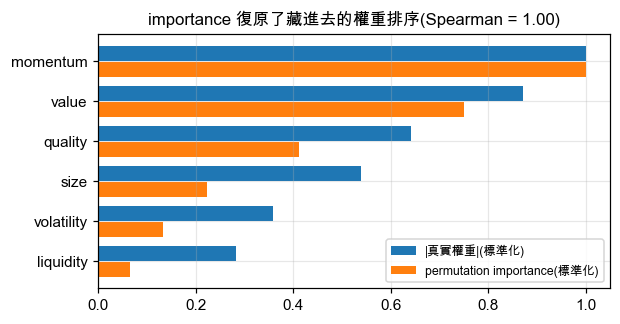

In [6]:
rf_syn = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=20,
                               max_features="sqrt", n_jobs=-1,
                               random_state=SEED).fit(Xtr_s, ytr_s)
pi = permutation_importance(rf_syn, Xte_s, yte_s, n_repeats=5,
                            random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FAC)
cmp_df = pd.DataFrame({"|true weight|": pd.Series(TRUE_W).abs(),
                       "perm importance": imp}).sort_values("perm importance", ascending=False)
rho = stats.spearmanr(cmp_df["|true weight|"], cmp_df["perm importance"]).statistic
print(cmp_df.round(4).to_string())
print(f"\nSpearman(|w|, importance) = {rho:.3f}   <- 1.0 代表排序完全復原")

fig, ax = plt.subplots(figsize=(6, 3))
o = cmp_df.index[::-1]
ax.barh(np.arange(len(o)) + .2, cmp_df.loc[o, "|true weight|"] / cmp_df["|true weight|"].max(),
        height=.38, label="|真實權重|(標準化)")
ax.barh(np.arange(len(o)) - .2, cmp_df.loc[o, "perm importance"] / cmp_df["perm importance"].max(),
        height=.38, label="permutation importance(標準化)")
ax.set_yticks(np.arange(len(o))); ax.set_yticklabels(o)
ax.set_title(f"importance 復原了藏進去的權重排序(Spearman = {rho:.2f})")
ax.legend(fontsize=8); savefig(fig, "03-importance-recovery"); plt.show()

## 1.3 噪音掃描 —— 第 3 部分結果的預告

前面兩節證明了機制沒問題。現在固定結構、**只調噪音 σ**,從 0.1 拉到 5.0,
看 OOS $R^2$ 怎麼衰減。

這張圖是整本 notebook 的伏筆:它說的是
**同一個模型在不同 SNR 下會給出從 0.90 到 0.004 的 $R^2$,而模型完全沒變。**

真實的月頻個股報酬在這條曲線上的位置:已知最強的橫截面報酬訊號(動能、反轉)
月頻 IC 大約在 0.0x 量級,而 $R^2 \approx \mathrm{IC}^2$,所以落在 $10^{-4} \sim 10^{-3}$ —— 
比這張圖最右端(σ=5.0)還要更右邊。

 sigma     SNR  ceiling  oos_r2
  0.10 44.3611   0.9780  0.9019
  0.25  7.0978   0.8765  0.8072
  0.50  1.7744   0.6396  0.5837
  0.75  0.7886   0.4409  0.3936
  1.00  0.4436   0.3073  0.2676
  1.50  0.1972   0.1647  0.1330
  2.00  0.1109   0.0998  0.0751
  3.00  0.0493   0.0470  0.0278
  4.00  0.0277   0.0270  0.0104
  5.00  0.0177   0.0174  0.0040


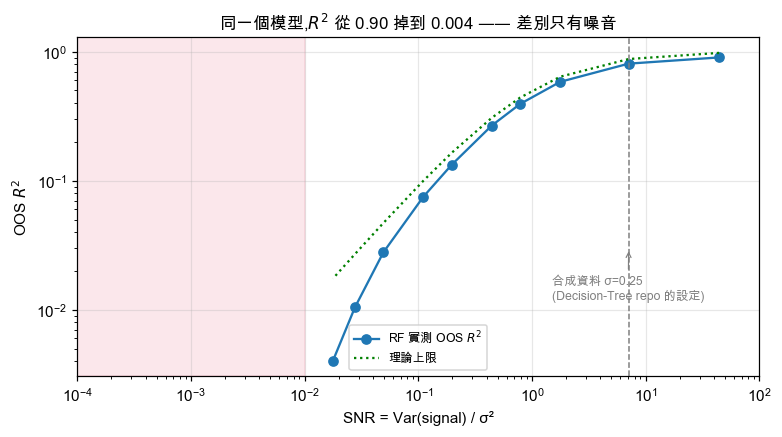

In [7]:
sigmas = np.array([0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0])
sweep = []
for s in sigmas:
    Xn, yn, sg = make_panel(sigma=float(s), seed=0)
    trn = Xn["month"] < 84
    rf = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=20,
                               max_features="sqrt", n_jobs=-1, random_state=SEED)
    rf.fit(Xn.loc[trn, FAC].values, yn[trn].values)
    r2 = r2_score(yn[~trn].values, rf.predict(Xn.loc[~trn, FAC].values))
    sweep.append(dict(sigma=s, SNR=sg.var() / s ** 2,
                      ceiling=sg.var() / (sg.var() + s ** 2), oos_r2=r2))
sweep = pd.DataFrame(sweep)
print(sweep.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep.SNR, sweep.oos_r2, "o-", label="RF 實測 OOS $R^2$")
ax.plot(sweep.SNR, sweep.ceiling, ":", c="green", label="理論上限")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("SNR = Var(signal) / σ²"); ax.set_ylabel("OOS $R^2$")
ax.axvspan(1e-4, 1e-2, color="crimson", alpha=.10)
ax.annotate("真實月頻個股報酬\n大約在這一帶\n($R^2\\sim10^{-4}$)", xy=(1.2e-3, 2e-3),
            fontsize=8, color="crimson", ha="center")
ax.axvline(7.1, ls="--", c="grey", lw=1)
ax.annotate("合成資料 σ=0.25\n(Decision-Tree repo 的設定)", xy=(7.1, 0.03),
            xytext=(1.5, 0.012), fontsize=8, color="grey",
            arrowprops=dict(arrowstyle="->", color="grey", lw=.8))
ax.set_title("同一個模型,$R^2$ 從 0.90 掉到 0.004 —— 差別只有噪音")
ax.legend(fontsize=8); ax.set_xlim(1e-4, 1e2)
savefig(fig, "04-noise-sweep"); plt.show()

**第 1 部分小結**

1. RF 在 SNR=7.1 的合成資料上拿到 OOS $R^2 \approx 0.81$,貼著理論上限 0.88 ——
   模型、評估、walk-forward 的切法都沒問題。
2. bagging 的價值是把預測器自身的 sd 砍掉一個數量級($1/\sqrt{n}$),不是降偏誤。
3. permutation importance 完整復原了藏進去的權重排序(Spearman = 1.0)。
4. 把噪音拉大,**同一個模型**的 $R^2$ 可以從 0.90 掉到 0.004。

所以如果第 3 部分任務 A 的 $R^2$ 是 0,「模型寫錯」這個解釋已經被排除了。
剩下的解釋只有一個:**$y$ 那邊沒有東西可以學。**

---
# 第 2 部分:真實資料的特徵工程

只有 OHLCV,所以不會有任何基本面因子(沒有 P/E、沒有 ROE)。
20 個特徵全部在**月底結算**,全部只用當天與之前的資料。

| 類別 | 特徵 | 定義 |
|---|---|---|
| 報酬 | `ret_1m` `ret_3m` `ret_6m` `ret_12m` | 月底收盤的 1/3/6/12 個月對數報酬 |
| | `ret_12_1` | 12 個月動能但跳過最近一個月(學術標準動能) |
| 風險 | `vol_21d` `vol_63d` `vol_252d` | 日對數報酬的滾動標準差 × √252 |
| | `downside_vol_63d` | 只取負報酬的 RMS × √252 |
| | `skew_63d` `kurt_63d` | 日報酬的滾動偏態 / 峰態 |
| 區間 | `parkinson_21d` | $\sqrt{\frac{1}{4\ln 2}\overline{\ln(H/L)^2}}\times\sqrt{252}$,用高低價估波動 |
| | `dist_52w_high` `dist_52w_low` | 收盤距 252 日高 / 低的比例 |
| | `max_dd_252d` | 252 日內最大回撤(用滾動高點近似) |
| 量能 | `dollar_vol_21d` | $\log(1+\overline{P\cdot V})$,市值與流動性的代理 |
| | `volume_trend` | $\log(\overline{V}_{21} / \overline{V}_{252})$,量能放大/縮小 |
| | `amihud_illiq_21d` | Amihud 非流動性 $\overline{|r| / (P V)}$ |
| 市場 | `beta_252d` | 對等權市場的 252 日 beta |
| | `idio_vol_252d` | 殘差波動 $\sqrt{\sigma_i^2-\beta_i^2\sigma_m^2}\times\sqrt{252}$ |

## 兩個標的

| | 定義 |
|---|---|
| `fwd_ret` | 下個月的月底對月底對數報酬 |
| `fwd_vol` | 下個月**當月**日對數報酬的標準差 × √252(已實現波動) |

兩個都做**逐月橫截面排序正規化**到 `(0,1]`。這一步是整本 notebook 能成立的關鍵:
原始的 `fwd_ret` 標準差約 0.12、`fwd_vol` 約 0.25,量綱完全不同,$R^2$ 不能比。
壓成同一個 uniform 分佈之後,「預測常數 0.5」的 $R^2$ 就是 0,兩個任務的數字就能並排看。

In [8]:
t0 = time.time()
close = px["Close"].astype("float64").where(lambda d: d > 0)
high  = px["High"].astype("float64").where(lambda d: d > 0)
low   = px["Low"].astype("float64").where(lambda d: d > 0)
volu  = px["Volume"].astype("float64").where(lambda d: d > 0)

lr = np.log(close).diff()
lr = lr.where(lr.abs() < 1.0)        # 砍掉 >±172% 的單日跳動(拆併股殘留)

mid = close.index.to_period("M")                               # 每天屬於哪個月
me_dates = pd.DatetimeIndex(pd.Series(close.index, index=mid)
                            .groupby(level=0).last().values)    # 每月最後一個交易日
at_me = lambda df: df.reindex(me_dates)                        # 日頻 -> 月底取樣
print(f"{len(me_dates)} 個月底  {me_dates[0].date()} ~ {me_dates[-1].date()}")

216 個月底  2007-01-31 ~ 2024-12-31


In [9]:
mc = close.groupby(mid).last(); mc.index = me_dates            # 月底收盤
n_days = lr.notna().groupby(mid).sum(); n_days.index = me_dates

F = {}
F["ret_1m"]   = np.log(mc / mc.shift(1))
F["ret_3m"]   = np.log(mc / mc.shift(3))
F["ret_6m"]   = np.log(mc / mc.shift(6))
F["ret_12m"]  = np.log(mc / mc.shift(12))
F["ret_12_1"] = np.log(mc.shift(1) / mc.shift(13))

for w, nm in [(21, "vol_21d"), (63, "vol_63d"), (252, "vol_252d")]:
    F[nm] = at_me(lr.rolling(w, min_periods=int(w * .6)).std()) * SQ252
neg = lr.where(lr < 0, 0.0).where(lr.notna())
F["downside_vol_63d"] = at_me(np.sqrt((neg ** 2).rolling(63, min_periods=40).mean())) * SQ252
F["skew_63d"] = at_me(lr.rolling(63, min_periods=40).skew())
F["kurt_63d"] = at_me(lr.rolling(63, min_periods=40).kurt())

F["parkinson_21d"] = at_me(np.sqrt((np.log(high / low) ** 2)
                                   .rolling(21, min_periods=13).mean() / (4 * np.log(2)))) * SQ252

roll_max = close.rolling(252, min_periods=150).max()
roll_min = close.rolling(252, min_periods=150).min()
F["dist_52w_high"] = at_me(close / roll_max - 1.0)
F["dist_52w_low"]  = at_me(close / roll_min - 1.0)
F["max_dd_252d"]   = at_me((close / roll_max - 1.0).rolling(252, min_periods=150).min())

dv = close * volu
F["dollar_vol_21d"]   = at_me(np.log1p(dv.rolling(21, min_periods=13).mean()))
F["volume_trend"]     = at_me(np.log(volu.rolling(21, min_periods=13).mean()
                                     / volu.rolling(252, min_periods=150).mean()))
F["amihud_illiq_21d"] = at_me(np.log1p((lr.abs() / dv * 1e9).rolling(21, min_periods=13).mean()))

mkt = lr.mean(axis=1)                                          # 等權市場
mm, vm = mkt.rolling(252, min_periods=150).mean(), mkt.rolling(252, min_periods=150).var()
rm  = lr.rolling(252, min_periods=150).mean()
cov = lr.mul(mkt, axis=0).rolling(252, min_periods=150).mean() - rm.mul(mm, axis=0)
beta = cov.div(vm, axis=0)
idio = np.sqrt((lr.rolling(252, min_periods=150).var() - beta.pow(2).mul(vm, axis=0)).clip(lower=0))
F["beta_252d"]     = at_me(beta)
F["idio_vol_252d"] = at_me(idio) * SQ252

FEATS = list(F)
print(f"{len(FEATS)} 個特徵 / {time.time()-t0:.1f}s")
print(FEATS)

20 個特徵 / 9.9s
['ret_1m', 'ret_3m', 'ret_6m', 'ret_12m', 'ret_12_1', 'vol_21d', 'vol_63d', 'vol_252d', 'downside_vol_63d', 'skew_63d', 'kurt_63d', 'parkinson_21d', 'dist_52w_high', 'dist_52w_low', 'max_dd_252d', 'dollar_vol_21d', 'volume_trend', 'amihud_illiq_21d', 'beta_252d', 'idio_vol_252d']


In [10]:
# ---- 兩個標的(都是「下個月」)
fwd_ret = np.log(mc.shift(-1) / mc)
rv_m = lr.groupby(mid).std(); rv_m.index = me_dates             # 當月已實現波動(日 sd)
fwd_vol = rv_m.shift(-1) * SQ252

panel = pd.concat({k: v.stack() for k, v in F.items()} |
                  {"fwd_ret": fwd_ret.stack(), "fwd_vol": fwd_vol.stack(),
                   "cur_vol_m": (rv_m * SQ252).stack(),          # 本月已實現波動(持續性基準)
                   "n_days": n_days.stack(), "fwd_nd": n_days.shift(-1).stack(),
                   "px": mc.stack()}, axis=1)
panel.index.names = ["month", "ticker"]

ok = (panel[FEATS].notna().all(axis=1) & panel["fwd_ret"].notna() & panel["fwd_vol"].notna()
      & (panel["n_days"] >= 15) & (panel["fwd_nd"] >= 15) & (panel["px"] >= 1.0))
P = panel[ok].copy()
print(f"原始 {len(panel):,} 列 -> 清理後 {len(P):,} 列 "
      f"({P.index.get_level_values(0).nunique()} 個月,"
      f"{P.index.get_level_values(0).min().date()} ~ {P.index.get_level_values(0).max().date()})")
cnt = P.groupby(level=0).size()
print(f"每月檔數 min {cnt.min()} / median {int(cnt.median())} / max {cnt.max()}")
print("\n逐年平均每月檔數:")
print(cnt.groupby(cnt.index.year).mean().round(0).astype(int).to_string())

原始 574,776 列 -> 清理後 372,623 列 (201 個月,2008-03-31 ~ 2024-11-29)
每月檔數 min 1356 / median 1790 / max 2568

逐年平均每月檔數:
month
2008    1370
2009    1398
2010    1436
2011    1474
2012    1516
2013    1558
2014    1616
2015    1706
2016    1793
2017    1865
2018    1941
2019    2030
2020    2108
2021    2216
2022    2390
2023    2522
2024    2553


清理條件:20 個特徵全部非 NaN、兩個標的非 NaN、當月與下月各至少 15 個交易日、月底收盤 ≥ \$1。

panel 從 2008-03 開始(不是 2007-01),因為 `ret_12_1` 需要 13 個月的歷史,
`vol_252d` / `beta_252d` 需要 252 個交易日 —— 第一年整個被特徵的視窗吃掉了。
這件事後面決定了 walk-forward 只能切出 12 個測試年,不是 13 個。

In [11]:
# ---- 正規化:特徵逐月橫截面 z-score、標的逐月橫截面排序到 (0,1]
g = P.groupby(level=0)
X = g[FEATS].transform(lambda s: (s - s.mean()) / (s.std(ddof=0) + 1e-12)).clip(-5, 5)
Y = pd.DataFrame({"ret": g["fwd_ret"].rank(pct=True),
                  "vol": g["fwd_vol"].rank(pct=True)})
months = X.index.get_level_values(0)
print("X", X.shape, " Y", Y.shape)
print("\n排序正規化後的標的分佈(兩個任務同尺度):")
print(Y.describe().round(4).to_string())

X (372623, 20)  Y (372623, 2)

排序正規化後的標的分佈(兩個任務同尺度):
               ret          vol
count  372623.0000  372623.0000
mean        0.5003       0.5003
std         0.2887       0.2887
min         0.0004       0.0004
25%         0.2503       0.2503
50%         0.5003       0.5003
75%         0.7503       0.7503
max         1.0000       1.0000


## 2.1 主題的前提:先用單變數 IC 證明兩個標的的可預測性差了兩個數量級

在訓練任何模型之前,先把這件事量出來。每個月算一次橫截面 Spearman 相關,
然後對 201 個月取平均,t 值用 $\bar{\mathrm{IC}}/\mathrm{sd}(\mathrm{IC})\times\sqrt{N}$。

In [12]:
def monthly_ic(pred, target):
    """逐月橫截面 Spearman IC;回傳 (每月 IC 的 Series, 平均, t 值)"""
    idx = pred.index
    tgt = target.loc[idx]
    ic = pred.groupby(level=0).apply(lambda s: stats.spearmanr(s, tgt.loc[s.index]).statistic)
    return ic, ic.mean(), ic.mean() / ic.std(ddof=1) * np.sqrt(len(ic))

prem = []
for lbl, pred, tgt in [("本月波動 → 下月波動", P["cur_vol_m"], Y["vol"]),
                       ("本月報酬 → 下月報酬", P["ret_1m"],   Y["ret"]),
                       ("12-1 動能 → 下月報酬", P["ret_12_1"], Y["ret"])]:
    _, m, t = monthly_ic(pred, tgt)
    prem.append(dict(關係=lbl, IC=round(m, 4), t=round(t, 1)))
print(pd.DataFrame(prem).to_string(index=False))

            關係      IC     t
   本月波動 → 下月波動  0.6726 132.6
   本月報酬 → 下月報酬 -0.0161  -1.9
12-1 動能 → 下月報酬  0.0055   0.5


                  ic_vol     t_vol  ic_ret   t_ret
feature                                           
max_dd_252d      -0.6319 -124.4117  0.0127  0.9174
dist_52w_high    -0.4765  -58.0128  0.0047  0.3592
dollar_vol_21d   -0.2436  -34.5245  0.0030  0.3649
ret_12m          -0.1242   -7.4157  0.0017  0.1593
ret_12_1         -0.1146   -6.9147  0.0055  0.5342
ret_6m           -0.1005   -6.2835 -0.0046 -0.4461
ret_3m           -0.0866   -5.7233 -0.0058 -0.6196
ret_1m           -0.0623   -4.4260 -0.0161 -1.9470
volume_trend     -0.0015   -0.2380 -0.0023 -0.6256
skew_63d          0.0586   12.8781 -0.0015 -0.3460
kurt_63d          0.0626   11.6085  0.0005  0.1282
dist_52w_low      0.2456   24.0761 -0.0069 -0.9118
amihud_illiq_21d  0.3600   55.1597 -0.0073 -0.8302
beta_252d         0.5077   63.9785 -0.0047 -0.3076
vol_21d           0.6727  133.2394 -0.0219 -1.7402
downside_vol_63d  0.7119  159.2588 -0.0188 -1.3765
idio_vol_252d     0.7210  153.0410 -0.0174 -1.5185
parkinson_21d     0.7275  163.8

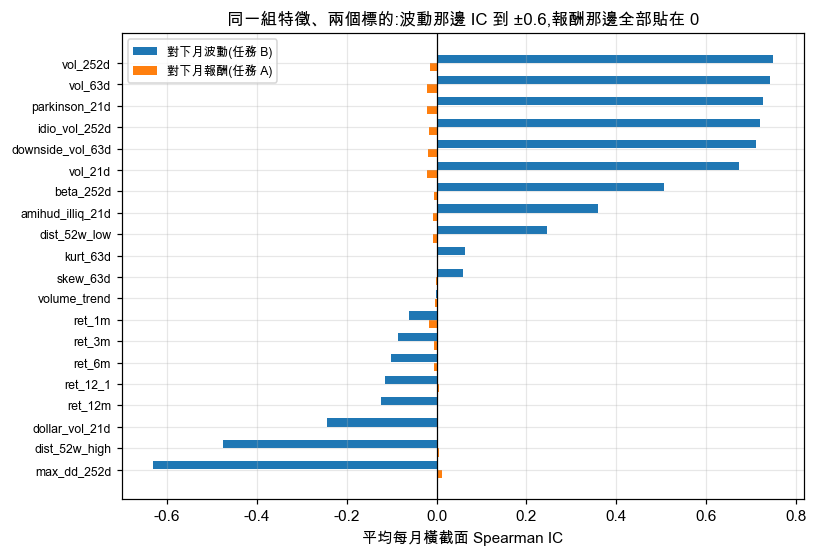

In [13]:
# 20 個特徵對兩個標的的單變數 IC —— 一張圖看完
rows = []
for f in FEATS:
    _, m_v, t_v = monthly_ic(X[f], Y["vol"])
    _, m_r, t_r = monthly_ic(X[f], Y["ret"])
    rows.append(dict(feature=f, ic_vol=m_v, t_vol=t_v, ic_ret=m_r, t_ret=t_r))
uni = pd.DataFrame(rows).set_index("feature").sort_values("ic_vol")
print(uni.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5.5))
yy = np.arange(len(uni))
ax.barh(yy + .2, uni.ic_vol, height=.38, label="對下月波動(任務 B)")
ax.barh(yy - .2, uni.ic_ret, height=.38, label="對下月報酬(任務 A)")
ax.set_yticks(yy); ax.set_yticklabels(uni.index, fontsize=8)
ax.axvline(0, c="k", lw=.8)
ax.set_xlabel("平均每月橫截面 Spearman IC")
ax.set_title("同一組特徵、兩個標的:波動那邊 IC 到 ±0.6,報酬那邊全部貼在 0")
ax.legend(fontsize=8)
savefig(fig, "05-univariate-ic"); plt.show()

---
# 第 3 部分:Walk-forward 訓練與對比(核心)

## 設計

```python
RandomForestRegressor(n_estimators=300, max_depth=12,
                      min_samples_leaf=200,    # 低 SNR 要大葉子
                      max_features="sqrt", n_jobs=-1, random_state=42)
```

- **展開視窗**:訓練集從 2008-03 開始,每年往後長一年;測試一整年。
- **測試年 2013–2024,共 12 個 fold。** 為什麼不是 13 個:panel 從 2008-03 才開始
  (12 個月的特徵視窗吃掉第一年),要維持「至少 ~5 年訓練」就只能從 2013 開始。
  2012 當測試年的話訓練集只剩 3.7 年,那條規則會先被違反。
- **1 個月 embargo**:測試年是 $Y$ 年,訓練集只用到 $Y-1$ 年 11 月的特徵列。
  被丟掉的是 $Y-1$ 年 12 月那一列 —— 它的標的落在 $Y$ 年 1 月,
  會和測試期的第一個標的視窗重疊。不丟就是洩漏。
- `min_samples_leaf=200`:在 IC 只有 0.0x 的資料上,小葉子等於直接記噪音。

兩個任務用**完全相同的 `X`、完全相同的超參數、完全相同的 fold 切法**,只換 `Y` 的那一欄。

In [14]:
RF_PARAMS = dict(n_estimators=300, max_depth=12, min_samples_leaf=200,
                 max_features="sqrt", n_jobs=-1, random_state=SEED)
TEST_YEARS = list(range(2013, 2025))

folds = []
for yr in TEST_YEARS:
    tr = months < pd.Timestamp(yr - 1, 12, 1)
    te = months.year == yr
    folds.append(dict(測試年=yr,
                      訓練月數=int(months[tr].nunique()),
                      訓練列數=int(tr.sum()),
                      測試列數=int(te.sum()),
                      訓練最後一月=str(months[tr].max().date())))
print(pd.DataFrame(folds).to_string(index=False))

 測試年  訓練月數   訓練列數  測試列數     訓練最後一月
2013    57  82065 18697 2012-11-30
2014    69 100703 19397 2013-11-29
2015    81 120031 20477 2014-11-28
2016    93 140418 21511 2015-11-30
2017   105 161839 22381 2016-11-30
2018   117 184155 23291 2017-11-30
2019   129 207375 24360 2018-11-30
2020   141 231634 25297 2019-11-29
2021   153 256839 26590 2020-11-30
2022   165 283314 28680 2021-11-30
2023   177 311793 30261 2022-11-30
2024   189 341997 28088 2023-11-30


In [15]:
t0 = time.time()
fold_rows, OOS = [], {}
for task in ["ret", "vol"]:
    parts = []
    for yr in TEST_YEARS:
        tr, te = months < pd.Timestamp(yr - 1, 12, 1), months.year == yr
        ts = time.time()
        rf = RandomForestRegressor(**RF_PARAMS).fit(X[tr].values, Y.loc[tr, task].values)
        yhat = pd.Series(rf.predict(X[te].values), index=X[te].index, name=task)
        parts.append(yhat)
        _, ic_m, _ = monthly_ic(yhat, Y[task])
        fold_rows.append(dict(task=task, year=yr, n_train=int(tr.sum()), n_test=int(te.sum()),
                              oos_r2=r2_score(Y.loc[te, task], yhat), ic=ic_m,
                              sec=round(time.time() - ts, 1)))
        print(f"[{task}] {yr}  train {int(tr.sum()):>7,}  test {int(te.sum()):>6,}  "
              f"R²={fold_rows[-1]['oos_r2']:+.4f}  IC={ic_m:+.4f}  ({fold_rows[-1]['sec']:.0f}s)")
    OOS[task] = pd.concat(parts)
print(f"\n總共 {len(fold_rows)} 個 fit / {time.time()-t0:.0f}s")
fold_df = pd.DataFrame(fold_rows)

[ret] 2013  train  82,065  test 18,697  R²=-0.0035  IC=-0.0059  (22s)


[ret] 2014  train 100,703  test 19,397  R²=-0.0006  IC=-0.0009  (35s)


[ret] 2015  train 120,031  test 20,477  R²=+0.0017  IC=+0.0244  (34s)


[ret] 2016  train 140,418  test 21,511  R²=-0.0014  IC=+0.0097  (42s)


[ret] 2017  train 161,839  test 22,381  R²=-0.0009  IC=+0.0040  (40s)


...

[vol] 2020  train 231,634  test 25,297  R²=+0.5515  IC=+0.7417  (46s)


[vol] 2021  train 256,839  test 26,590  R²=+0.6794  IC=+0.8237  (55s)


[vol] 2022  train 283,314  test 28,680  R²=+0.7053  IC=+0.8379  (61s)


[vol] 2023  train 311,793  test 30,261  R²=+0.6259  IC=+0.7888  (385s)


[vol] 2024  train 341,997  test 28,088  R²=+0.6531  IC=+0.8071  (724s)

總共 24 個 fit / 2141s


In [16]:
summary = []
IC = {}
for task in ["ret", "vol"]:
    yh = OOS[task]
    ic, m, t = monthly_ic(yh, Y[task])
    IC[task] = ic
    summary.append(dict(任務={"ret": "A:下月報酬", "vol": "B:下月波動"}[task],
                        OOS_R2=round(r2_score(Y.loc[yh.index, task], yh), 4),
                        IC=round(m, 4), IC_t=round(t, 1),
                        IC_sd=round(ic.std(ddof=1), 4),
                        IC為正的月份比例=f"{100*(ic>0).mean():.0f}%",
                        測試月數=len(ic)))
IC = pd.DataFrame(IC)
print(pd.DataFrame(summary).to_string(index=False))
print("\n逐 fold:")
print(fold_df.pivot(index="year", columns="task", values=["oos_r2", "ic"]).round(4).to_string())

    任務  OOS_R2     IC  IC_t  IC_sd IC為正的月份比例  測試月數
A:下月報酬 -0.0002 0.0158   2.0 0.0932       52%   143
B:下月波動  0.6143 0.7772 156.9 0.0592      100%   143

逐 fold:
      oos_r2              ic        
task     ret     vol     ret     vol
year                                
2013 -0.0035  0.5428 -0.0059  0.7332
2014 -0.0006  0.6009 -0.0009  0.7758
2015  0.0017  0.5735  0.0244  0.7511
2016 -0.0014  0.5937  0.0097  0.7666
2017 -0.0009  0.5869  0.0040  0.7631
2018  0.0002  0.5639  0.0190  0.7453
2019  0.0046  0.6340  0.0690  0.7941
2020 -0.0054  0.5515 -0.0227  0.7417
2021  0.0004  0.6794  0.0277  0.8237
2022  0.0014  0.7053  0.0251  0.8379
2023 -0.0000  0.6259  0.0207  0.7888
2024  0.0005  0.6531  0.0203  0.8071


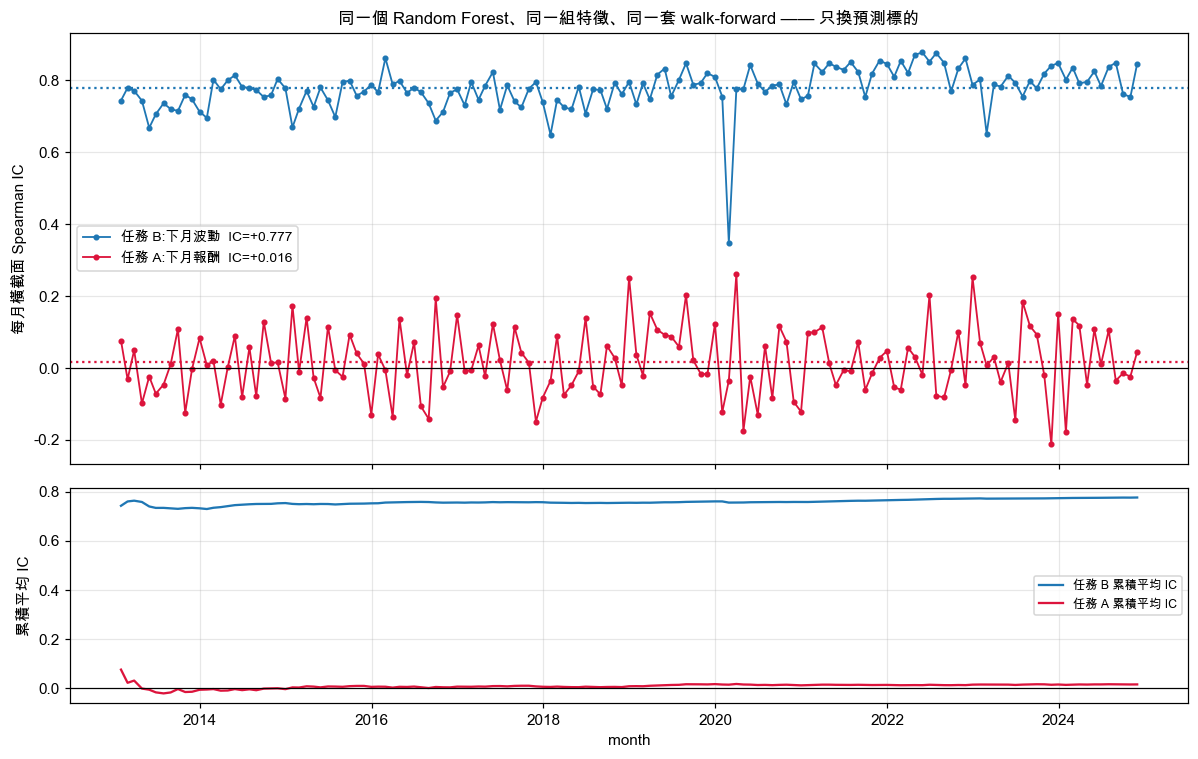

In [17]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
a1.plot(IC.index, IC["vol"], "-o", ms=3, lw=1.2, label=f"任務 B:下月波動  IC={IC['vol'].mean():+.3f}")
a1.plot(IC.index, IC["ret"], "-o", ms=3, lw=1.2, c="crimson",
        label=f"任務 A:下月報酬  IC={IC['ret'].mean():+.3f}")
a1.axhline(0, c="k", lw=.8)
a1.axhline(IC["vol"].mean(), ls=":", c="tab:blue"); a1.axhline(IC["ret"].mean(), ls=":", c="crimson")
a1.set_ylabel("每月橫截面 Spearman IC")
a1.set_title("同一個 Random Forest、同一組特徵、同一套 walk-forward —— 只換預測標的")
a1.legend(loc="center left", fontsize=9)
a2.plot(IC.index, IC["vol"].expanding().mean(), label="任務 B 累積平均 IC")
a2.plot(IC.index, IC["ret"].expanding().mean(), c="crimson", label="任務 A 累積平均 IC")
a2.axhline(0, c="k", lw=.8); a2.set_ylabel("累積平均 IC"); a2.set_xlabel("month")
a2.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "06-ic-timeseries"); plt.show()

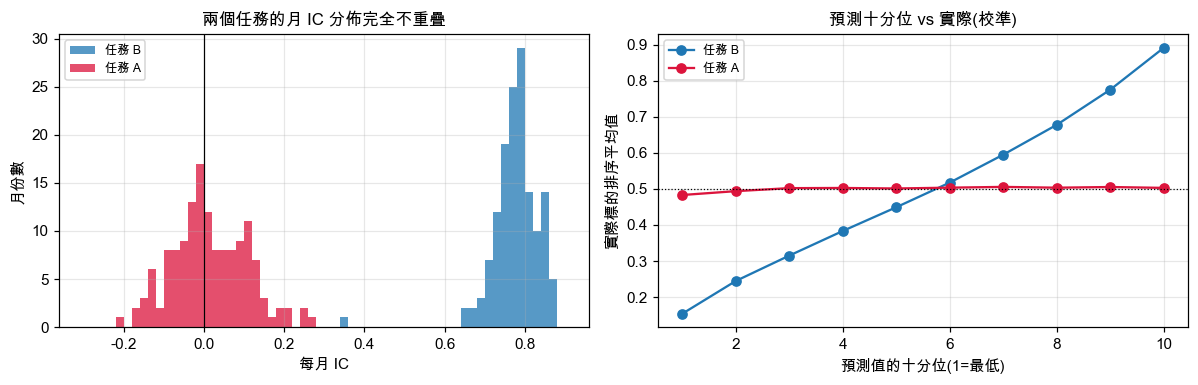

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(-0.3, 0.9, 61)
a1.hist(IC["vol"], bins=bins, alpha=.75, label="任務 B")
a1.hist(IC["ret"], bins=bins, alpha=.75, color="crimson", label="任務 A")
a1.axvline(0, c="k", lw=.8); a1.set_xlabel("每月 IC"); a1.set_ylabel("月份數")
a1.set_title("兩個任務的月 IC 分佈完全不重疊"); a1.legend(fontsize=8)
for task, c in [("vol", "tab:blue"), ("ret", "crimson")]:
    yh = OOS[task]; yt = Y.loc[yh.index, task]
    q = pd.qcut(yh.groupby(level=0).rank(pct=True), 10, labels=False)
    a2.plot(np.arange(1, 11), yt.groupby(q).mean().values, "o-", c=c,
            label={"vol": "任務 B", "ret": "任務 A"}[task])
a2.axhline(0.5, c="k", lw=.8, ls=":")
a2.set_xlabel("預測值的十分位(1=最低)"); a2.set_ylabel("實際標的排序平均值")
a2.set_title("預測十分位 vs 實際(校準)"); a2.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "07-ic-dist-calibration"); plt.show()

## 3.1 RF 到底比「什麼都不做」好多少

任務 B 的 IC 很高,但有個很尷尬的問題必須問:**那是模型的功勞,還是波動度自己的自相關?**
「本月波動」這一個數字的 IC 就是 0.673(見 2.1),
如果 RF 用 20 個特徵跑出來也只有那個數字,那模型什麼都沒加。

任務 A 同理,基準是純 12-1 動能與純反轉。這一節把 RF 和「一行程式的基準」放在同一個
樣本期、同一個 OOS 區間上比。

In [19]:
idx = OOS["vol"].index          # 兩個任務的 OOS 索引相同
base_rows = []
for lbl, pred, task in [
        ("RF(20 特徵)",            OOS["vol"],            "vol"),
        ("基準:cur_vol_m(本月波動)", P.loc[idx, "cur_vol_m"], "vol"),
        ("基準:vol_21d",            P.loc[idx, "vol_21d"],   "vol"),
        ("基準:parkinson_21d",      P.loc[idx, "parkinson_21d"], "vol"),
        ("RF(20 特徵)",            OOS["ret"],            "ret"),
        ("基準:ret_12_1(動能)",    P.loc[idx, "ret_12_1"],  "ret"),
        ("基準:-ret_1m(反轉)",     -P.loc[idx, "ret_1m"],   "ret")]:
    ic, m, t = monthly_ic(pred, Y[task])
    base_rows.append(dict(任務={"vol": "B 波動", "ret": "A 報酬"}[task], 預測=lbl,
                          IC=round(m, 4), IC_t=round(t, 1)))
base_df = pd.DataFrame(base_rows)
print(base_df.to_string(index=False))

d_ic = (IC["vol"] - monthly_ic(P.loc[idx, "cur_vol_m"], Y["vol"])[0])
print(f"\n任務 B:RF 相對本月波動基準的逐月 IC 增量 = {d_ic.mean():+.4f} "
      f"(t = {d_ic.mean()/d_ic.std(ddof=1)*np.sqrt(len(d_ic)):+.1f},"
      f"{100*(d_ic>0).mean():.0f}% 的月份為正)")

  任務                 預測     IC  IC_t
B 波動          RF(20 特徵) 0.7772 156.9
B 波動 基準:cur_vol_m(本月波動) 0.6610 106.2
B 波動         基準:vol_21d 0.6613 106.6
B 波動   基準:parkinson_21d 0.7208 128.6
A 報酬          RF(20 特徵) 0.0158   2.0
A 報酬    基準:ret_12_1(動能) 0.0102   0.9
A 報酬     基準:-ret_1m(反轉) 0.0170   1.8



任務 B:RF 相對本月波動基準的逐月 IC 增量 = +0.1161 (t = +29.9,100% 的月份為正)


---
# 第 4 部分:任務 A 的現實檢驗

任務 A 的平均 IC 是 +0.016,t 值 +2.0 —— 剛好壓在「兩個標準差」那條線上。
這種數字最危險:它不夠小到可以直接丟掉,但也絕對不夠大到能下單。

所以這一節把它當成真的策略測一次:

- 每月按預測值排十分位,**多最高分位、空最低分位,等權**
- **交易成本單邊 10bp**,用實際換手率計(每月 $\sum_i |w_{i,t} - w_{i,t-1}| \times 10\text{bp}$)
- 對標兩個一行程式的基準:純 12-1 動能、純反轉
- 兩個 universe:全樣本、以及**每月成交金額前 1000 名**(這才是真的能下單的範圍)

報酬用簡單報酬 `exp(log_ret)-1` 做投組加總(對數報酬不能直接加權平均)。

In [20]:
idx = OOS["vol"].index                 # 兩個任務的 OOS 列完全相同
PO = P.loc[idx]
simple = np.expm1(PO["fwd_ret"])       # 投組加總要用簡單報酬
liquid = PO["dollar_vol_21d"].groupby(level=0).rank(ascending=False) <= 1000
COST = 0.0010                          # 單邊 10bp

def long_short(score, mask=None, n_bins=10, cost=COST):
    """每月十分位多空、等權。回傳 (毛報酬, 淨報酬, 每月換手)。"""
    if mask is not None:
        score = score[mask]
    s = score.groupby(level=0).rank(pct=True)
    L, S = s > 1 - 1/n_bins, s <= 1/n_bins
    w = pd.Series(0.0, index=s.index)
    w[L] =  1.0 / L.groupby(level=0).transform("sum")[L]
    w[S] = -1.0 / S.groupby(level=0).transform("sum")[S]
    wide = w.unstack().fillna(0.0)
    ret = simple[s.index].unstack().reindex_like(wide).fillna(0.0)
    gross = (wide * ret).sum(axis=1)
    turn = wide.diff().abs().sum(axis=1)
    turn.iloc[0] = wide.abs().sum(axis=1).iloc[0]
    return gross, gross - turn * cost, turn

def perf(r, lbl, turn=None):
    ann, vol = r.mean() * 12, r.std(ddof=1) * np.sqrt(12)
    eq = (1 + r).cumprod()
    return {"策略": lbl, "年化報酬": round(ann, 4), "年化波動": round(vol, 4),
            "Sharpe": round(ann / vol, 2),
            "t值": round(r.mean() / r.std(ddof=1) * np.sqrt(len(r)), 2),
            "最大回撤": round((eq / eq.cummax() - 1).min(), 3),
            "勝率": f"{100*(r>0).mean():.0f}%",
            "月換手": "" if turn is None else round(turn.mean(), 2)}

SIGNALS = [("RF 預測報酬", OOS["ret"]), ("12-1 動能", PO["ret_12_1"]), ("反轉 (-ret_1m)", -PO["ret_1m"])]
rows, curves = [], {}
for uni, mask in [("全樣本", None), ("流動性前 1000", liquid)]:
    for lbl, sc in SIGNALS:
        gr, nt, tn = long_short(sc, mask)
        rows.append(perf(gr, f"[{uni}] {lbl} 毛"))
        rows.append(perf(nt, f"[{uni}] {lbl} 淨 10bp", tn))
        curves[(uni, lbl)] = nt
print(pd.DataFrame(rows).to_string(index=False))

                             策略    年化報酬   年化波動  Sharpe    t值   最大回撤  勝率   月換手
                [全樣本] RF 預測報酬 毛 -0.1058 0.1635   -0.65 -2.23 -0.763 40%      
           [全樣本] RF 預測報酬 淨 10bp -0.1325 0.1634   -0.81 -2.80 -0.828 38%  2.23
                [全樣本] 12-1 動能 毛 -0.0162 0.2017   -0.08 -0.28 -0.534 55%      
           [全樣本] 12-1 動能 淨 10bp -0.0281 0.2017   -0.14 -0.48 -0.576 54%   1.0
           [全樣本] 反轉 (-ret_1m) 毛  0.0631 0.1720    0.37  1.27 -0.300 51%      
      [全樣本] 反轉 (-ret_1m) 淨 10bp  0.0226 0.1721    0.13  0.45 -0.341 46%  3.37
          [流動性前 1000] RF 預測報酬 毛 -0.0665 0.1949   -0.34 -1.18 -0.656 44%      
     [流動性前 1000] RF 預測報酬 淨 10bp -0.0963 0.1950   -0.49 -1.70 -0.759 41%  2.48
          [流動性前 1000] 12-1 動能 毛  0.0848 0.2191    0.39  1.34 -0.363 55%      
     [流動性前 1000] 12-1 動能 淨 10bp  0.0703 0.2191    0.32  1.11 -0.369 52%   1.2
     [流動性前 1000] 反轉 (-ret_1m) 毛  0.0069 0.1876    0.04  0.13 -0.351 46%      
[流動性前 1000] 反轉 (-ret_1m) 淨 10bp -0.0346 0.1876   -0.18 -0.64 -0.

**結果**:RF 的報酬預測不只是「無法拒絕為 0」,它的十分位多空價差是**負的**(全樣本毛 Sharpe −0.65)。
這跟 +0.016 的正 IC 看起來矛盾,但一看十分位的組成就懂了。

               實際年化報酬(簡單平均)  中位 vol_21d    中位股價  中位 log 成交金額  平均 ret_1m(上月報酬)
預測十分位(0=預測最差)                                                                
0                     0.261       0.482  18.730       16.029            0.055
1                     0.179       0.360  26.269       16.500            0.058
2                     0.165       0.330  32.580       16.906            0.045
3                     0.156       0.316  35.229       17.113            0.029
4                     0.140       0.304  36.348       17.073            0.011
5                     0.146       0.293  35.796       17.030           -0.004
6                     0.153       0.278  34.964       16.891           -0.016
7                     0.139       0.263  34.001       16.778           -0.023
8                     0.155       0.251  32.666       16.641           -0.030
9                     0.154       0.270  23.960       15.934           -0.057


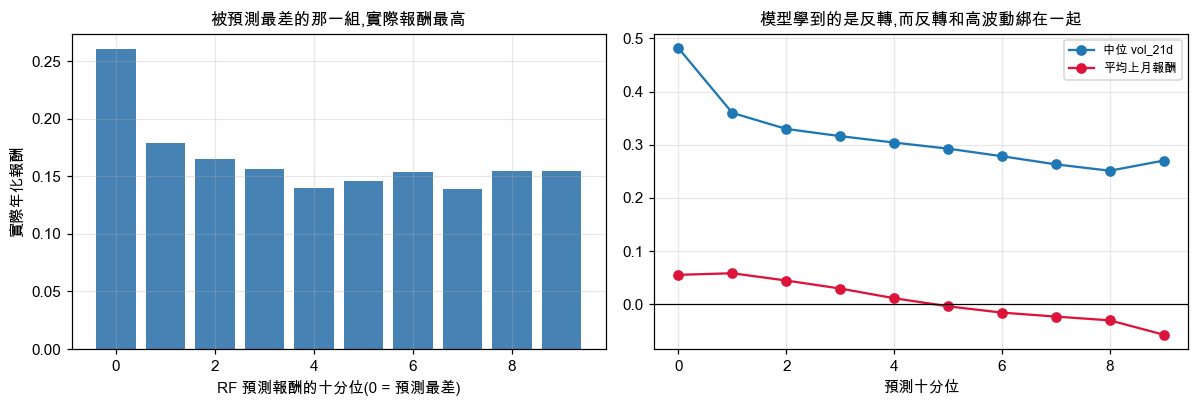

In [21]:
dec = (OOS["ret"].groupby(level=0).rank(pct=True) * 10).clip(upper=9.999).astype(int)
prof = pd.DataFrame({
    "實際年化報酬(簡單平均)": simple.groupby(dec).mean() * 12,
    "中位 vol_21d": PO["vol_21d"].groupby(dec).median(),
    "中位股價": PO["px"].groupby(dec).median(),
    "中位 log 成交金額": PO["dollar_vol_21d"].groupby(dec).median(),
    "平均 ret_1m(上月報酬)": PO["ret_1m"].groupby(dec).mean()})
prof.index.name = "預測十分位(0=預測最差)"
print(prof.round(3).to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.bar(prof.index, prof.iloc[:, 0], color="steelblue")
a1.set_xlabel("RF 預測報酬的十分位(0 = 預測最差)"); a1.set_ylabel("實際年化報酬")
a1.set_title("被預測最差的那一組,實際報酬最高")
a2.plot(prof.index, prof["中位 vol_21d"], "o-", label="中位 vol_21d")
a2.plot(prof.index, prof["平均 ret_1m(上月報酬)"], "o-", c="crimson", label="平均上月報酬")
a2.axhline(0, c="k", lw=.8); a2.set_xlabel("預測十分位"); a2.legend(fontsize=8)
a2.set_title("模型學到的是反轉,而反轉和高波動綁在一起")
fig.tight_layout(); savefig(fig, "08-decile-profile"); plt.show()

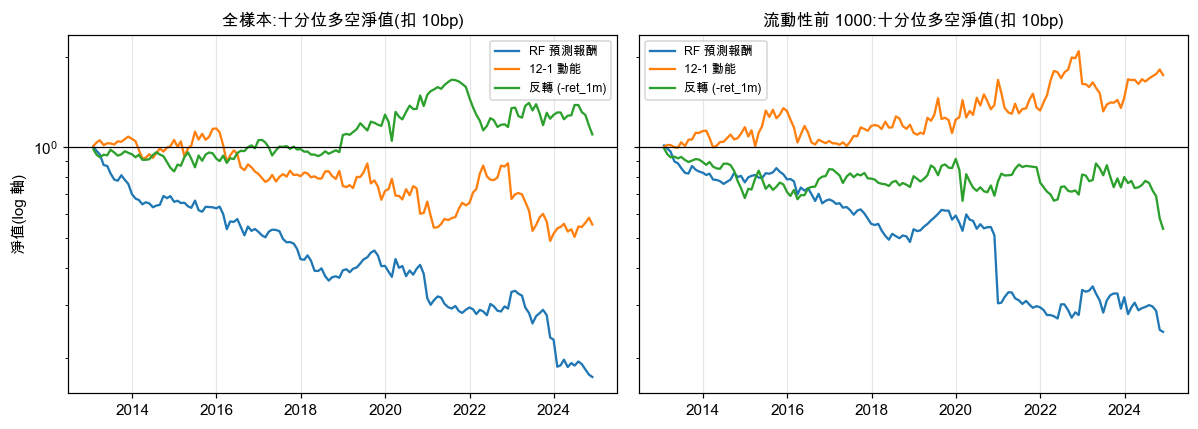

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, uni in zip(axes, ["全樣本", "流動性前 1000"]):
    for lbl, _ in SIGNALS:
        r = curves[(uni, lbl)]
        ax.plot(r.index, (1 + r).cumprod(), label=lbl)
    ax.axhline(1, c="k", lw=.8); ax.set_yscale("log")
    ax.set_title(f"{uni}:十分位多空淨值(扣 10bp)"); ax.legend(fontsize=8)
axes[0].set_ylabel("淨值(log 軸)")
fig.tight_layout(); savefig(fig, "09-longshort-equity"); plt.show()

## 4.1 這一節真正的教訓:rank IC 和錢不是同一件事

三件事同時成立,而且不矛盾:

1. RF 對報酬的**排序**有一點點正相關(IC +0.016,t=+2.0);
2. 它的十分位**價差是負的**(毛 Sharpe −0.65,t=−2.2);
3. 兩邊都不足以當策略。

原因在十分位的組成表裡:模型學到的其實是**短期反轉**
(預測最差的那一組,平均上月報酬 +5.5%;預測最好的那一組,上月 −5.7%),
而上月漲最多的那批股票同時也是**波動最高、股價最低**的那批。
高波動股票的簡單報酬平均數被波動本身推高(對數報酬的凸性),
於是「預測最差」的那一組實際年化報酬反而最高。

排序正規化把報酬的**量綱整個丟掉了**,IC 只看順序,看不到這件事。
這是把 IC 當 KPI 的標準陷阱 —— 也是為什麼第 4 部分非做不可:
如果只看第 3 部分的 IC 表,任務 A 看起來「弱但有一點東西」;
真的下單就會發現那一點東西是負的。

流動性前 1000 的版本:RF 淨 Sharpe −0.49、動能 +0.32、反轉 −0.18,t 值全部在 ±2 內 ——
**在能下單的範圍內,三個訊號都無法拒絕為 0。**

---
# 第 5 部分:任務 B 成功了,然後呢

任務 B 的 IC 是 0.78,但「IC 很高」不等於「能用」。這一節做三件事:

1. **校準**:預測五分位的實際下月波動是否真的分開
2. **部位 sizing**:等風險 vs 等金額,風險有沒有真的被拉平
3. **選擇權權利金品質**:高預測波動的名單長什麼樣(純橫截面示意,不接任何帳戶資料)

前置作業:模型輸出的是 `(0,1]` 的排序,要用就得換回**波動的水準**。
做法是用當月橫截面 `cur_vol_m` 的分位函數把 rank 映回水準
(只用月底當天已知的資訊,沒有未來函數)。

In [23]:
rank_v = OOS["vol"].groupby(level=0).rank(pct=True)

def rank_to_level(g):
    cur = PO.loc[g.index, "cur_vol_m"].values
    return pd.Series(np.quantile(cur, np.clip(g.values, 1e-6, 1 - 1e-6)), index=g.index)

vol_hat = rank_v.groupby(level=0, group_keys=False).apply(rank_to_level)

cmp_rows = []
for nm, v in [("RF vol_hat", vol_hat), ("基準 cur_vol_m", PO["cur_vol_m"])]:
    b, a = np.polyfit(v, PO["fwd_vol"], 1)
    cmp_rows.append(dict(預測=nm, Pearson_corr=round(np.corrcoef(v, PO["fwd_vol"])[0, 1], 3),
                         R2=round(np.corrcoef(v, PO["fwd_vol"])[0, 1] ** 2, 3),
                         MAE=round((v - PO["fwd_vol"]).abs().mean(), 4),
                         迴歸斜率=round(b, 3), 截距=round(a, 3)))
print(pd.DataFrame(cmp_rows).to_string(index=False))

          預測  Pearson_corr    R2    MAE  迴歸斜率    截距
  RF vol_hat         0.660 0.436 0.1210 0.661 0.127
基準 cur_vol_m         0.574 0.330 0.1404 0.575 0.160


水準版本 RF 也贏:$R^2$ 0.44 vs 0.33,MAE 0.121 vs 0.140。

但迴歸斜率 0.66 < 1 要特別講:**rank→水準的映射在極端端過度外推**。
把 rank 0.998 丟進當月橫截面的分位函數,拿到的是當月最極端的那個波動值,
而下個月通常會往中間回歸。要真的要水準的精度,應該直接拿 `log(fwd_vol)` 當標的訓練 ——
但那就不是「同一個 pipeline 只換 y」了,所以這本 notebook 不做。
下面用到水準的地方(sizing)都要記得它偏高。

       檔數  本月已實現波動(中位)  下月已實現波動(中位)  下月已實現波動(平均)  下月波動 sd
Q1  57725        0.182        0.191        0.217    0.139
Q2  57803        0.241        0.244        0.274    0.149
Q3  57809        0.294        0.293        0.330    0.176
Q4  57803        0.374        0.367        0.414    0.215
Q5  57890        0.583        0.558        0.641    0.361

五分位中位數逐月嚴格單調遞增的月份比例: 100%  (143 個月)


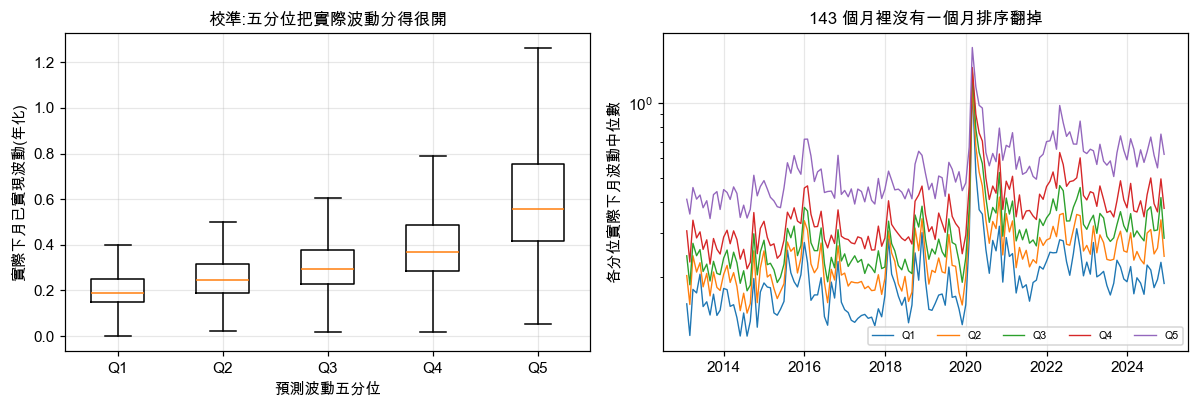

In [24]:
qv = (rank_v * 5).clip(upper=4.999).astype(int)
cal = pd.DataFrame({"檔數": PO.groupby(qv).size(),
                    "本月已實現波動(中位)": PO.groupby(qv)["cur_vol_m"].median(),
                    "下月已實現波動(中位)": PO.groupby(qv)["fwd_vol"].median(),
                    "下月已實現波動(平均)": PO.groupby(qv)["fwd_vol"].mean(),
                    "下月波動 sd": PO.groupby(qv)["fwd_vol"].std()})
cal.index = [f"Q{i+1}" for i in cal.index]
print(cal.round(3).to_string())
mono = PO.groupby([PO.index.get_level_values(0), qv])["fwd_vol"].median().unstack()
print(f"\n五分位中位數逐月嚴格單調遞增的月份比例:"
      f" {100*(mono.diff(axis=1).iloc[:, 1:] > 0).all(axis=1).mean():.0f}%  ({len(mono)} 個月)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.boxplot([PO["fwd_vol"][qv == i].values for i in range(5)], showfliers=False,
           tick_labels=[f"Q{i+1}" for i in range(5)])
a1.set_xlabel("預測波動五分位"); a1.set_ylabel("實際下月已實現波動(年化)")
a1.set_title("校準:五分位把實際波動分得很開")
for i in range(5):
    a2.plot(mono.index, mono[i], lw=.9, label=f"Q{i+1}")
a2.set_yscale("log"); a2.set_ylabel("各分位實際下月波動中位數"); a2.legend(fontsize=7, ncol=5)
a2.set_title("143 個月裡沒有一個月排序翻掉")
fig.tight_layout(); savefig(fig, "10-vol-calibration"); plt.show()

## 5.1 部位 sizing:等風險 vs 等金額

檢驗方式是把下月報酬用「事前的風險估計」標準化:

$$z_i = \frac{r_{i,t+1}}{\hat{\sigma}_i / \sqrt{12}}$$

如果風險估得準,$z$ 的標準差應該**在各波動分位之間一樣**(等風險的定義)。
等金額那一列就是沒有除、直接看原始報酬的離散度。

           風險估計  整體_sd_z   Q1   Q2   Q3   Q4   Q5  最高最低比
      等金額(不除風險)    0.447 0.24 0.29 0.35 0.45 0.73   2.98
除本月波動 cur_vol_m    1.334 1.69 1.23 1.21 1.23 1.23   0.73
除 RF 預測 vol_hat    1.220 1.55 1.19 1.13 1.11 1.05   0.68

            加權  年化報酬  年化波動  Sharpe  滾動12M波動_sd  滾動12M波動_max
           等金額 0.140 0.173    0.81      0.0680        0.333
   1/cur_vol_m 0.134 0.153    0.88      0.0609        0.301
1/vol_hat (RF) 0.131 0.150    0.87      0.0594        0.297


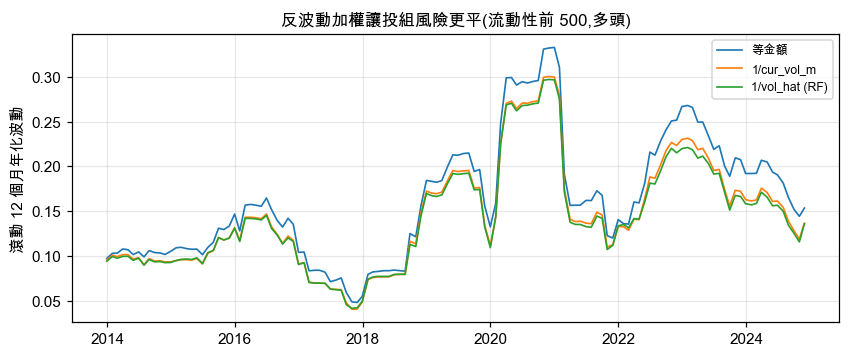

In [25]:
size_rows = []
for nm, v in [("等金額(不除風險)", pd.Series(1.0, index=PO.index)),
              ("除本月波動 cur_vol_m", PO["cur_vol_m"]),
              ("除 RF 預測 vol_hat", vol_hat)]:
    z = PO["fwd_ret"] / (v / np.sqrt(12))
    byq = z.groupby(qv).std()
    size_rows.append(dict(風險估計=nm, 整體_sd_z=round(z.std(), 3),
                          **{f"Q{i+1}": round(byq.iloc[i], 2) for i in range(5)},
                          最高最低比=round(byq.iloc[-1] / byq.iloc[0], 2)))
print(pd.DataFrame(size_rows).to_string(index=False))

# 投組層級:流動性前 500,等金額 vs 反波動加權
liq500 = PO["dollar_vol_21d"].groupby(level=0).rank(ascending=False) <= 500
def portfolio(w):
    ww = w[liq500]
    ww = ww / ww.groupby(level=0).transform("sum")
    return (ww * simple[liq500]).groupby(level=0).sum()
port_rows, port_curves = [], {}
for nm, w in [("等金額", pd.Series(1.0, index=PO.index)),
              ("1/cur_vol_m", 1 / PO["cur_vol_m"]), ("1/vol_hat (RF)", 1 / vol_hat)]:
    r = portfolio(w); roll = r.rolling(12).std() * np.sqrt(12)
    port_rows.append(dict(加權=nm, 年化報酬=round(r.mean() * 12, 3),
                          年化波動=round(r.std(ddof=1) * np.sqrt(12), 3),
                          Sharpe=round(r.mean() * 12 / (r.std(ddof=1) * np.sqrt(12)), 2),
                          滾動12M波動_sd=round(roll.std(), 4),
                          滾動12M波動_max=round(roll.max(), 3)))
    port_curves[nm] = roll
print()
print(pd.DataFrame(port_rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.4))
for nm, roll in port_curves.items():
    ax.plot(roll.index, roll, label=nm, lw=1.1)
ax.set_ylabel("滾動 12 個月年化波動"); ax.set_title("反波動加權讓投組風險更平(流動性前 500,多頭)")
ax.legend(fontsize=8); savefig(fig, "11-risk-sizing"); plt.show()

兩個觀察:

- **等風險真的把風險拉平了**:等金額的 $z$ 標準差從低波動分位的 0.24 一路升到高波動分位的 0.73
  (差 3 倍);除掉 `vol_hat` 之後變成 1.55 → 1.05(差 0.68 倍,方向還反過來)。
  最低波動那一組 $z$ 的 sd 仍然偏大,是因為低波動股票的報酬相對自己的波動有更厚的尾。
- **但 RF 相對「直接用本月波動」的增量很小**:Sharpe 0.87 vs 0.88、
  滾動 12M 波動的 sd 0.0594 vs 0.0609。
  這完全符合整本 notebook 的主題:**可預測性在標的那邊,換更好的模型只拿到邊際的改善。**

## 5.2 選擇權權利金品質(純示意)

這是我真的在用的場景:賣 covered call 的時候要判斷「這個權利金貴不貴」,
而權利金貴不貴取決於**未來一個月的實際波動**會不會撐得起隱含波動。
橫截面的下月波動預測剛好就是這個問題的其中一半。

下面只做示意:取最後一個 OOS 月份(2024-11-29),在流動性前 500 名裡
印出預測下月波動**最高**與**最低**各幾檔,並且把**實際發生的** 2024-12 波動放在旁邊對照。
不接任何帳戶持倉資料 —— 這本 notebook 要能公開。

In [26]:
m_last = PO.index.get_level_values(0).max()
snap = pd.DataFrame({"預測波動分位": rank_v.loc[m_last], "vol_hat": vol_hat.loc[m_last],
                     "本月已實現": PO["cur_vol_m"].loc[m_last],
                     "下月實際(2024-12)": PO["fwd_vol"].loc[m_last],
                     "log成交金額": PO["dollar_vol_21d"].loc[m_last],
                     "股價": PO["px"].loc[m_last]})
snap = snap[snap["log成交金額"] >= snap["log成交金額"].quantile(1 - 500 / len(snap))]
print(f"{m_last.date()} 月底,流動性前 500 內 —— 預測下月波動最高 12 檔:")
print(snap.nlargest(12, "預測波動分位").round(3).to_string())
print("\n預測最低 8 檔:")
print(snap.nsmallest(8, "預測波動分位").round(3).to_string())
hi = snap.nlargest(50, "預測波動分位")["下月實際(2024-12)"].median()
lo = snap.nsmallest(50, "預測波動分位")["下月實際(2024-12)"].median()
print(f"\n前 50 檔 vs 後 50 檔,2024-12 實際已實現波動中位數:{hi:.3f} vs {lo:.3f}(差 {hi/lo:.1f} 倍)")

2024-11-29 月底,流動性前 500 內 —— 預測下月波動最高 12 檔:
        預測波動分位  vol_hat  本月已實現  下月實際(2024-12)  log成交金額      股價
ticker                                                        
DJT      0.998    2.754  1.544          0.569   21.285   31.60
SMCI     0.995    2.223  1.902          1.142   21.792   32.64
LUNR     0.994    2.039  1.418          1.158   19.369   16.35
WULF     0.990    1.902  1.250          1.330   19.106    7.89
SMR      0.988    1.832  1.129          0.879   19.488   29.65
ASTS     0.984    1.596  0.967          0.686   19.388   23.81
MSTR     0.982    1.554  1.523          1.016   23.336  387.47
MARA     0.979    1.449  1.564          0.822   21.340   27.42
HUT      0.978    1.419  1.192          1.077   19.082   28.02
SOUN     0.978    1.414  1.391          1.768   19.675    9.31
IONQ     0.977    1.410  1.536          1.525   20.554   36.50
HIMS     0.970    1.297  1.687          0.777   20.245   32.22

預測最低 8 檔:
        預測波動分位  vol_hat  本月已實現  下月實際(2024-12)  log成交金額       股價


這張表就是任務 B 能換到的東西:
月底的時候,**在真的能下單的流動性範圍內**,把下個月會不會晃分成兩堆,
而且事後對照 2024-12 的實際波動,排序是對的。

接到選擇權的用法(這本 notebook 不做,只說清楚介面):
高分位名單是賣 call 的權利金可能撐得住的地方(IV 高有實際波動支撐 → 但也更容易被叫走),
低分位名單是賣 call 收不到錢的地方(權利金便宜不是因為便宜,是因為真的不會動)。
真正要下單還差一半 —— **隱含波動**。這本 notebook 只處理已實現波動那一半。

---
# 第 6 部分:模型診斷

三件事:

1. **Permutation importance**(不用 impurity importance:後者對高基數特徵有系統性偏誤)
2. 兩個任務的 importance 對比
3. `n_estimators` 學習曲線 + OOB score

都在最後一個 fold(訓練到 2023-11、測試 2024 全年)上做。

In [27]:
tr_l, te_l = months < pd.Timestamp(2023, 12, 1), months.year == 2024
Xtr_l, Xte_l = X[tr_l].values, X[te_l].values
diag, IMP, CURVE = {}, {}, {}
for task in ["ret", "vol"]:
    rf = RandomForestRegressor(**(RF_PARAMS | dict(oob_score=True)))
    rf.fit(Xtr_l, Y.loc[tr_l, task].values)
    yt = Y.loc[te_l, task].values
    pi = permutation_importance(rf, Xte_l, yt, n_repeats=5, random_state=0,
                                n_jobs=-1, scoring="r2")
    IMP[task] = pd.Series(pi.importances_mean, index=FEATS)
    # 單一森林直接做學習曲線:每棵樹的預測取累積平均
    tp = np.array([t.predict(Xte_l) for t in rf.estimators_])
    cum = np.cumsum(tp, 0) / np.arange(1, len(tp) + 1)[:, None]
    ks = [1, 2, 3, 5, 10, 20, 50, 100, 200, 300]
    CURVE[task] = pd.DataFrame({"n_estimators": ks,
                                "oos_r2": [r2_score(yt, cum[k - 1]) for k in ks],
                                "ic": [stats.spearmanr(cum[k - 1], yt).statistic for k in ks]})
    diag[task] = dict(任務={"ret": "A 報酬", "vol": "B 波動"}[task],
                      OOB_R2=round(rf.oob_score_, 4),
                      測試_R2=round(r2_score(yt, rf.predict(Xte_l)), 4),
                      permutation_importance_總和=round(IMP[task].clip(lower=0).sum(), 5),
                      為負的特徵數=int((IMP[task] < 0).sum()))
print(pd.DataFrame(diag.values()).to_string(index=False))

  任務  OOB_R2  測試_R2  permutation_importance_總和  為負的特徵數
A 報酬  0.0043 0.0005                    0.00291      12
B 波動  0.6183 0.6531                    0.20122       0


                      ret      vol
vol_252d         -0.00036  0.05285
vol_63d           0.00016  0.04497
parkinson_21d     0.00056  0.03829
downside_vol_63d  0.00060  0.01970
idio_vol_252d     0.00068  0.01326
kurt_63d         -0.00023  0.00845
vol_21d           0.00060  0.00500
dist_52w_high    -0.00034  0.00367
skew_63d         -0.00007  0.00269
beta_252d        -0.00062  0.00251
max_dd_252d      -0.00050  0.00234
volume_trend      0.00009  0.00174
ret_12_1          0.00001  0.00142
dist_52w_low      0.00022  0.00127
ret_12m          -0.00013  0.00116
ret_6m           -0.00008  0.00077
amihud_illiq_21d -0.00028  0.00040
ret_3m           -0.00054  0.00034
ret_1m           -0.00106  0.00024
dollar_vol_21d   -0.00008  0.00017

任務 B:前 5 大特徵佔正 importance 的 84%,全部是波動類特徵
任務 A:20 個特徵的 importance 全部落在 [-0.00106, +0.00068],其中 12 個是負的


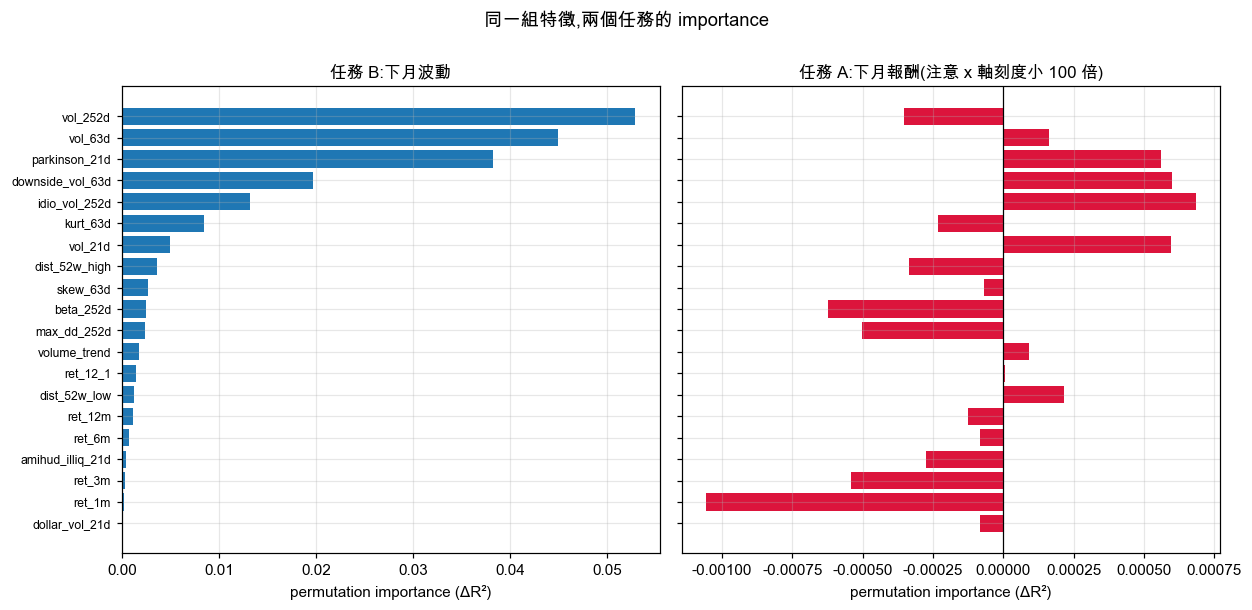

In [28]:
imp_df = pd.DataFrame(IMP).sort_values("vol")
print(imp_df.sort_values("vol", ascending=False).round(5).to_string())
print(f"\n任務 B:前 5 大特徵佔正 importance 的 "
      f"{100*imp_df['vol'].nlargest(5).sum()/imp_df['vol'].clip(lower=0).sum():.0f}%,"
      f"全部是波動類特徵")
print(f"任務 A:20 個特徵的 importance 全部落在 "
      f"[{imp_df['ret'].min():+.5f}, {imp_df['ret'].max():+.5f}],"
      f"其中 {(imp_df['ret']<0).sum()} 個是負的")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.5), sharey=True)
yy = np.arange(len(imp_df))
axes[0].barh(yy, imp_df["vol"], color="tab:blue")
axes[0].set_title("任務 B:下月波動"); axes[0].set_xlabel("permutation importance (ΔR²)")
axes[0].set_yticks(yy); axes[0].set_yticklabels(imp_df.index, fontsize=8)
axes[1].barh(yy, imp_df["ret"], color="crimson")
axes[1].axvline(0, c="k", lw=.8)
axes[1].set_title("任務 A:下月報酬(注意 x 軸刻度小 100 倍)")
axes[1].set_xlabel("permutation importance (ΔR²)")
fig.suptitle("同一組特徵,兩個任務的 importance", y=1.00)
fig.tight_layout(); savefig(fig, "12-permutation-importance"); plt.show()

                 ret             vol        
              oos_r2      ic  oos_r2      ic
n_estimators                                
1            -0.0055  0.0068  0.6329  0.7943
2            -0.0028  0.0115  0.6444  0.8014
3            -0.0030  0.0072  0.6478  0.8035
5            -0.0016  0.0087  0.6500  0.8050
10           -0.0001  0.0173  0.6522  0.8064
20            0.0003  0.0206  0.6529  0.8069
50            0.0001  0.0189  0.6527  0.8068
100           0.0004  0.0200  0.6527  0.8068
200           0.0006  0.0209  0.6530  0.8070
300           0.0005  0.0214  0.6531  0.8070


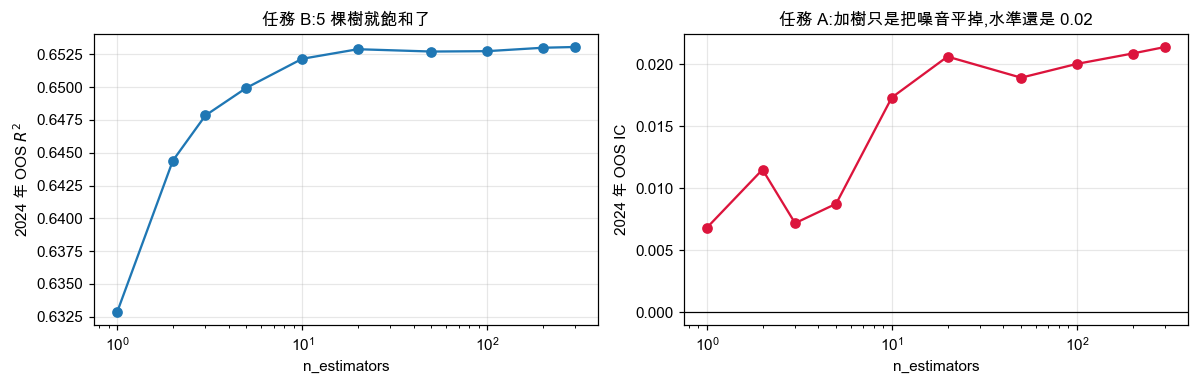

In [29]:
print(pd.concat({k: v.set_index("n_estimators") for k, v in CURVE.items()}, axis=1).round(4).to_string())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(CURVE["vol"].n_estimators, CURVE["vol"].oos_r2, "o-")
a1.set_xscale("log"); a1.set_xlabel("n_estimators"); a1.set_ylabel("2024 年 OOS $R^2$")
a1.set_title("任務 B:5 棵樹就飽和了")
a2.plot(CURVE["ret"].n_estimators, CURVE["ret"].ic, "o-", c="crimson")
a2.axhline(0, c="k", lw=.8); a2.set_xscale("log"); a2.set_xlabel("n_estimators")
a2.set_ylabel("2024 年 OOS IC"); a2.set_title("任務 A:加樹只是把噪音平掉,水準還是 0.02")
fig.tight_layout(); savefig(fig, "13-learning-curve"); plt.show()

**診斷結論**

- 任務 B 的 importance **集中在波動類特徵**:`vol_252d`、`vol_63d`、`parkinson_21d`、
  `downside_vol_63d`、`idio_vol_252d` 就佔了正 importance 的 84%。
  模型沒有學到什麼奇怪的東西,它學到的就是「波動有記憶」,而且把不同視窗的波動估計加權混起來
  比單用任何一個視窗好:對照 3.1 節,`cur_vol_m` 0.661、`vol_21d` 0.661、
  最強的單一特徵 `parkinson_21d` 也只有 0.721,RF 是 0.777。
- 任務 A 的 importance **全部落在 ±0.001 以內,而且有一半是負的**
  (負 = 把那個特徵打亂之後 $R^2$ 反而變好)。這不是「重要性散成一片噪音」,
  是**根本沒有訊號可以分配**。
- OOB $R^2$:任務 B 0.618 / 測試 0.653(OOB 略保守,正常);
  任務 A OOB 0.004 / 測試 0.001 —— 連 OOB 都看不到東西。
- 學習曲線:任務 B 第 5 棵樹就到 0.650(300 棵是 0.653),
  因為訊號又強又平滑,bagging 幾乎沒事可做 —— 和第 1 部分合成資料(1 棵 0.644 → 300 棵 0.807)
  正好相反。任務 A 的 IC 從 1 棵的 0.007 升到 300 棵的 0.021,
  那是把單棵樹的噪音平掉而已,水準還是 0.02。

---
# 小結

## 1. 同一個模型,兩個標的,差兩個數量級

| | 任務 A:下月報酬 | 任務 B:下月波動 |
|---|---|---|
| Pooled OOS $R^2$ | −0.0002 | **+0.614** |
| 平均每月 IC | +0.016 | **+0.777** |
| IC 的 t 值 | +2.0 | +156.9 |
| IC > 0 的月份 | 52% | **100%** |
| 十分位多空淨 Sharpe | −0.81 | (不適用) |
| 最強單一特徵的 IC | 0.017(`-ret_1m` 反轉) | 0.721(`parkinson_21d`) |

特徵一樣、超參數一樣、fold 切法一樣、embargo 一樣、資料一樣。**只有 `y` 不一樣。**

## 2. 限制在標的,不在模型

第 1 部分已經把「模型壞了」這個解釋排除掉:同一份程式在合成資料上拿到
$R^2$ 0.81(上限 0.88),importance 完整復原藏進去的權重排序(Spearman 1.0)。
第 1.3 節的噪音掃描更直接:**同一個模型**,把 SNR 從 44 降到 0.018,
$R^2$ 從 0.90 掉到 0.004。真實月頻個股報酬的 SNR 比那條曲線的最右端還要再低一到兩個數量級。

所以換 XGBoost、換 LightGBM、換神經網路,不會改變任務 A 的結果 ——
那些方法改善的是**偏誤與函數族**,而任務 A 缺的是**訊號**。
這和 CNN notebook 的結論同一個形狀:那邊的瓶頸在 `Flatten` 不在卷積層,
換更花的卷積核沒有用,因為 99.87% 的參數壓在後面那層 `Linear`。
**把失敗歸因到正確的地方,比把失敗修掉更重要 —— 因為有些失敗不能修。**

## 3. 而且「弱但有一點」比「完全沒有」更危險

任務 A 的 IC t 值是 +2.0,正好在一般論文會宣稱顯著的那條線上。
但第 4 部分把它當策略跑,十分位價差是**負的**(淨 Sharpe −0.81),
因為模型學到的是短期反轉,而反轉和高波動、低股價綁在一起,
排序正規化把這件事藏起來了。**rank IC 和錢不是同一件事。**

## 4. 存活者偏誤

這份 universe 是今天的 Russell 3000 回填到 2007,2008–2024 間下市、破產、被併的公司不在裡面。
這讓任務 A 的結果**偏樂觀**(左尾被截掉,動能/反轉類訊號看起來比真實情況好)——
連偏樂觀的版本都做不出報酬。對任務 B 影響小,因為波動的持續性是個股自身的統計性質,
不靠橫截面的贏家輸家排序。

## 5. 這份資料能做什麼、不能做什麼

| 能 | 不能 |
|---|---|
| 橫截面波動度預測(IC 0.78,143 個月 100% 為正) | 橫截面報酬預測(IC 0.016,扣成本後是負的) |
| 等風險部位 sizing、風險分群、選擇權的已實現波動那一半 | 隱含波動、IV/RV 比(這份資料沒有選擇權報價) |
| 跨景氣循環的穩健性檢查(含 2008、2020、2022) | 真實的下市/破產風險(存活者偏誤) |
| 日頻 OHLCV 能造出來的量價特徵 | 任何基本面因子(沒有財報資料) |

## 6. 如果要再往下做

1. **直接拿 `log(fwd_vol)` 當標的**訓練,取代 rank → 水準的分位映射(第 5 部分的斜率 0.66 就是這個問題)
2. 把波動預測接到**真的選擇權報價**上,算 IV/RV 比,才有「權利金貴不貴」的完整答案
3. 報酬那邊如果要繼續,正確的方向不是換模型,是**換資料**:
   point-in-time 基本面、分析師修正、持股變動、新聞 —— 也就是去找訊號,不是去找更好的擬合器